In [ ]:
import os
print(os.listdir())


['.config', 'shopping_trends.csv.csv', 'sample_data']


from google.colab import files
uploaded = files.upload()


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving shopping_trends.csv.csv to shopping_trends.csv (1).csv


In [ ]:
import pandas as pd

filename = list(uploaded.keys())[0]
print("Uploaded:", filename)

df = pd.read_csv(filename)
print("Shape:", df.shape)
df.head()

Uploaded: shopping_trends.csv (1).csv
Shape: (3900, 19)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


In [ ]:
print("Shape:", df.shape)
df.info()

Shape: (3900, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   obj

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64

Duplicate rows: 0


In [ ]:
print(df.describe())

       Customer ID          Age  Purchase Amount (USD)  Review Rating  \
count  3900.000000  3900.000000            3900.000000    3900.000000   
mean   1950.500000    44.068462              59.764359       3.749949   
std    1125.977353    15.207589              23.685392       0.716223   
min       1.000000    18.000000              20.000000       2.500000   
25%     975.750000    31.000000              39.000000       3.100000   
50%    1950.500000    44.000000              60.000000       3.700000   
75%    2925.250000    57.000000              81.000000       4.400000   
max    3900.000000    70.000000             100.000000       5.000000   

       Previous Purchases  
count         3900.000000  
mean            25.351538  
std             14.447125  
min              1.000000  
25%             13.000000  
50%             25.000000  
75%             38.000000  
max             50.000000  


In [ ]:
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].nunique()} unique -> {list(df[col].unique()[:6])}")

Gender: 2 unique -> ['Male', 'Female']
Item Purchased: 25 unique -> ['Blouse', 'Sweater', 'Jeans', 'Sandals', 'Sneakers', 'Shirt']
Category: 4 unique -> ['Clothing', 'Footwear', 'Outerwear', 'Accessories']
Location: 50 unique -> ['Kentucky', 'Maine', 'Massachusetts', 'Rhode Island', 'Oregon', 'Wyoming']
Size: 4 unique -> ['L', 'S', 'M', 'XL']
Color: 25 unique -> ['Gray', 'Maroon', 'Turquoise', 'White', 'Charcoal', 'Silver']
Season: 4 unique -> ['Winter', 'Spring', 'Summer', 'Fall']
Subscription Status: 2 unique -> ['Yes', 'No']
Payment Method: 6 unique -> ['Credit Card', 'Bank Transfer', 'Cash', 'PayPal', 'Venmo', 'Debit Card']
Shipping Type: 6 unique -> ['Express', 'Free Shipping', 'Next Day Air', 'Standard', '2-Day Shipping', 'Store Pickup']
Discount Applied: 2 unique -> ['Yes', 'No']
Promo Code Used: 2 unique -> ['Yes', 'No']
Preferred Payment Method: 6 unique -> ['Venmo', 'Cash', 'Credit Card', 'PayPal', 'Bank Transfer', 'Debit Card']
Frequency of Purchases: 7 unique -> ['Fortnight

In [ ]:
# Do the two payment columns ever differ?
print((df["Payment Method"] != df["Preferred Payment Method"]).sum(), "rows differ")

3283 rows differ


Columns: ['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount_usd', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'payment_method', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'preferred_payment_method', 'frequency_of_purchases', 'age_group', 'spend_level', 'payment_mismatch']

Age groups:
 age_group
18-25     571
26-35     742
36-45     729
46-55     753
56-70    1105
Name: count, dtype: int64

Spend levels:
 spend_level
High      1447
Medium    1393
Low       1060
Name: count, dtype: int64

--- Q1: Revenue by category ---
             total_revenue  avg_spend  orders
category                                     
Clothing            104264      60.03    1737
Accessories          74200      59.84    1240
Footwear             36093      60.26     599
Outerwear            18524      57.17     324

--- Q2: Subscribers vs non-subscribers ---
                     avg_spend  total_revenue  customers

NameError: name 'plt' is not defined

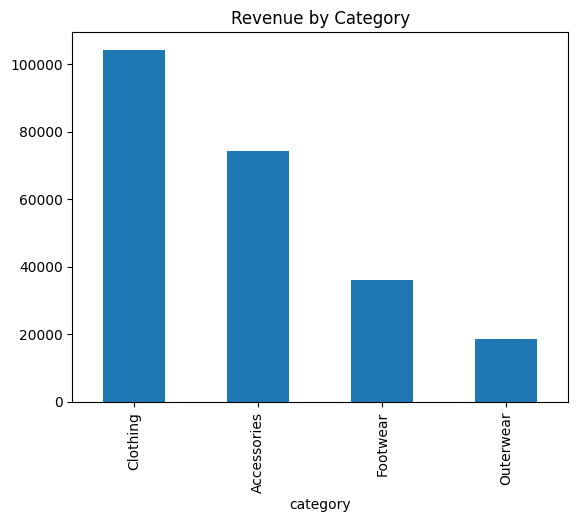

In [ ]:
# --- Day 2: cleaning ---
df_clean = df.copy()
df_clean.columns = (
    df_clean.columns.str.strip().str.lower()
    .str.replace(r"\s*\(usd\)", "", regex=True)
    .str.replace(" ", "_")
)
df_clean = df_clean.rename(columns={"purchase_amount": "purchase_amount_usd"})

df_clean["age_group"] = pd.cut(df_clean["age"], bins=[17, 25, 35, 45, 55, 70],
                               labels=["18-25", "26-35", "36-45", "46-55", "56-70"])
df_clean["spend_level"] = pd.cut(df_clean["purchase_amount_usd"], bins=[0, 40, 70, 100],
                                 labels=["Low", "Medium", "High"])
df_clean["payment_mismatch"] = df_clean["payment_method"] != df_clean["preferred_payment_method"]

print("Columns:", df_clean.columns.tolist())
print("\nAge groups:\n", df_clean["age_group"].value_counts().sort_index())
print("\nSpend levels:\n", df_clean["spend_level"].value_counts())

# --- Day 3: first business questions ---
print("\n--- Q1: Revenue by category ---")
q1 = (df_clean.groupby("category")["purchase_amount_usd"]
      .agg(total_revenue="sum", avg_spend="mean", orders="count")
      .sort_values("total_revenue", ascending=False).round(2))
print(q1)

print("\n--- Q2: Subscribers vs non-subscribers ---")
q2 = (df_clean.groupby("subscription_status")["purchase_amount_usd"]
      .agg(avg_spend="mean", total_revenue="sum", customers="count").round(2))
print(q2)

print("\n--- Q3: Avg spend by age group and gender ---")
q3 = df_clean.pivot_table(index="age_group", columns="gender",
                          values="purchase_amount_usd", aggfunc="mean", observed=True).round(2)
print(q3)

q1["total_revenue"].plot(kind="bar", title="Revenue by Category")
plt.ylabel("Revenue (USD)")
plt.show()

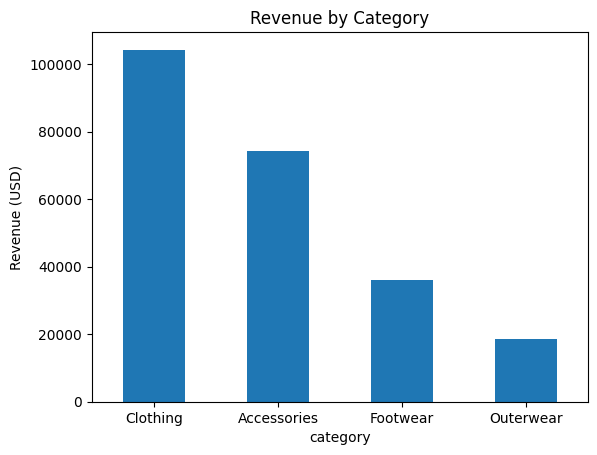

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

q1["total_revenue"].plot(kind="bar", title="Revenue by Category")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=0)
plt.show()


In [ ]:
# Q4: Do discounts change spend or rating?
q4 = (df_clean.groupby("discount_applied")
      .agg(avg_spend=("purchase_amount_usd", "mean"),
           avg_rating=("review_rating", "mean"),
           orders=("customer_id", "count")).round(2))
print("--- Q4: Discount impact ---\n", q4)

# Q5: Season performance
q5 = (df_clean.groupby("season")["purchase_amount_usd"]
      .agg(total_revenue="sum", avg_spend="mean", orders="count")
      .sort_values("total_revenue", ascending=False).round(2))
print("\n--- Q5: Season ---\n", q5)

# Q6: Top 10 locations by revenue
q6 = (df_clean.groupby("location")["purchase_amount_usd"]
      .agg(total_revenue="sum", orders="count")
      .sort_values("total_revenue", ascending=False).head(10))
print("\n--- Q6: Top locations ---\n", q6)

# Q7: Purchase frequency and loyalty
q7 = (df_clean.groupby("frequency_of_purchases")
      .agg(customers=("customer_id", "count"),
           avg_spend=("purchase_amount_usd", "mean"),
           avg_previous=("previous_purchases", "mean")).round(2)
      .sort_values("customers", ascending=False))
print("\n--- Q7: Frequency ---\n", q7)

--- Q4: Discount impact ---
                   avg_spend  avg_rating  orders
discount_applied                               
No                    60.13        3.76    2223
Yes                   59.28        3.74    1677

--- Q5: Season ---
         total_revenue  avg_spend  orders
season                                  
Fall            60018      61.56     975
Spring          58679      58.74     999
Winter          58607      60.36     971
Summer          55777      58.41     955

--- Q6: Top locations ---
                total_revenue  orders
location                            
Montana                 5784      96
Illinois                5617      92
California              5605      95
Idaho                   5587      93
Nevada                  5514      87
Alabama                 5261      89
New York                5257      87
North Dakota            5220      83
West Virginia           5174      81
Nebraska                5172      87

--- Q7: Frequency ---
                 

In [ ]:
df_clean["frequency_of_purchases"] = df_clean["frequency_of_purchases"].replace({
    "Bi-Weekly": "Fortnightly",
    "Every 3 Months": "Quarterly"
})
print(df_clean["frequency_of_purchases"].value_counts())

frequency_of_purchases
Quarterly      1147
Fortnightly    1089
Annually        572
Monthly         553
Weekly          539
Name: count, dtype: int64


In [ ]:
df_clean.to_csv("shopping_trends_clean.csv", index=False)

from google.colab import files
files.download("shopping_trends_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(df_clean.groupby("item_purchased")["purchase_amount_usd"]
      .agg(revenue="sum", orders="count").sort_values("revenue", ascending=False).head(5))
print(df_clean.groupby("promo_code_used")["purchase_amount_usd"].mean().round(2))
print(df_clean.groupby("shipping_type")["purchase_amount_usd"].agg(["mean", "count"]).round(2))

                revenue  orders
item_purchased                 
Blouse            10410     171
Shirt             10332     169
Dress             10320     166
Pants             10090     171
Jewelry           10010     171
promo_code_used
No     60.13
Yes    59.28
Name: purchase_amount_usd, dtype: float64
                 mean  count
shipping_type               
2-Day Shipping  60.73    627
Express         60.48    646
Free Shipping   60.41    675
Next Day Air    58.63    648
Standard        58.46    654
Store Pickup    59.89    650


In [ ]:
import sqlite3

conn = sqlite3.connect("shopping.db")

df_sql = df_clean.copy()
df_sql["age_group"] = df_sql["age_group"].astype(str)
df_sql["spend_level"] = df_sql["spend_level"].astype(str)
df_sql["payment_mismatch"] = df_sql["payment_mismatch"].astype(int)

df_sql.to_sql("shopping", conn, if_exists="replace", index=False)

def run(query):
    return pd.read_sql_query(query, conn)

run("SELECT COUNT(*) AS total_rows FROM shopping")

,total_rows
0,3900


In [ ]:
# 1. Revenue by category (GROUP BY, aggregates)
run("""
SELECT category,
       SUM(purchase_amount_usd) AS total_revenue,
       ROUND(AVG(purchase_amount_usd), 2) AS avg_spend,
       COUNT(*) AS orders
FROM shopping
GROUP BY category
ORDER BY total_revenue DESC
""")

,category,total_revenue,avg_spend,orders
0,Clothing,104264,60.03,1737
1,Accessories,74200,59.84,1240
2,Footwear,36093,60.26,599
3,Outerwear,18524,57.17,324


In [ ]:
# 2. Revenue share of each category (window function over aggregate)
run("""
SELECT category,
       SUM(purchase_amount_usd) AS revenue,
       ROUND(100.0 * SUM(purchase_amount_usd) / SUM(SUM(purchase_amount_usd)) OVER (), 1) AS pct_of_total
FROM shopping
GROUP BY category
ORDER BY revenue DESC
""")

,category,revenue,pct_of_total
0,Clothing,104264,44.7
1,Accessories,74200,31.8
2,Footwear,36093,15.5
3,Outerwear,18524,7.9


In [ ]:
# 3. Subscribers vs non-subscribers (GROUP BY)
run("""
SELECT subscription_status,
       COUNT(*) AS purchases,
       ROUND(AVG(purchase_amount_usd), 2) AS avg_spend
FROM shopping
GROUP BY subscription_status
""")

,subscription_status,purchases,avg_spend
0,No,2847,59.87
1,Yes,1053,59.49


In [ ]:
# 4. Spend segments with CASE WHEN
run("""
SELECT CASE WHEN purchase_amount_usd >= 70 THEN 'High'
            WHEN purchase_amount_usd >= 40 THEN 'Medium'
            ELSE 'Low' END AS spend_segment,
       COUNT(*) AS purchases
FROM shopping
GROUP BY spend_segment
ORDER BY purchases DESC
""")

,spend_segment,purchases
0,High,1491
1,Medium,1395
2,Low,1014


In [ ]:
# 5. HAVING: states with revenue above 5,500
run("""
SELECT location, SUM(purchase_amount_usd) AS revenue
FROM shopping
GROUP BY location
HAVING SUM(purchase_amount_usd) > 5500
ORDER BY revenue DESC
""")

,location,revenue
0,Montana,5784
1,Illinois,5617
2,California,5605
3,Idaho,5587
4,Nevada,5514


In [ ]:
# 6. RANK: top 3 items inside each category (CTE + window function)
run("""
WITH item_rev AS (
    SELECT category, item_purchased, SUM(purchase_amount_usd) AS revenue
    FROM shopping
    GROUP BY category, item_purchased
),
ranked AS (
    SELECT *, RANK() OVER (PARTITION BY category ORDER BY revenue DESC) AS rnk
    FROM item_rev
)
SELECT category, item_purchased, revenue, rnk
FROM ranked
WHERE rnk <= 3
ORDER BY category, rnk
""")

,category,item_purchased,revenue,rnk
0,Accessories,Jewelry,10010,1
1,Accessories,Sunglasses,9649,2
2,Accessories,Belt,9635,3
3,Clothing,Blouse,10410,1
4,Clothing,Shirt,10332,2
5,Clothing,Dress,10320,3
6,Footwear,Shoes,9240,1
7,Footwear,Sandals,9200,2
8,Footwear,Boots,9018,3
9,Outerwear,Coat,9275,1


In [ ]:
# 7. Season performance with running comparison to the best season
run("""
SELECT season,
       SUM(purchase_amount_usd) AS revenue,
       SUM(purchase_amount_usd) - MAX(SUM(purchase_amount_usd)) OVER () AS gap_vs_best
FROM shopping
GROUP BY season
ORDER BY revenue DESC
""")

,season,revenue,gap_vs_best
0,Fall,60018,0
1,Spring,58679,-1339
2,Winter,58607,-1411
3,Summer,55777,-4241


In [ ]:
# 8. Discount impact (GROUP BY on two measures)
run("""
SELECT discount_applied,
       COUNT(*) AS orders,
       ROUND(AVG(purchase_amount_usd), 2) AS avg_spend,
       ROUND(AVG(review_rating), 2) AS avg_rating
FROM shopping
GROUP BY discount_applied
""")

,discount_applied,orders,avg_spend,avg_rating
0,No,2223,60.13,3.76
1,Yes,1677,59.28,3.74


In [ ]:
# 9. Age group by gender with percentage of group (CTE)
run("""
WITH grp AS (
    SELECT age_group, gender, COUNT(*) AS n
    FROM shopping
    GROUP BY age_group, gender
)
SELECT age_group, gender, n,
       ROUND(100.0 * n / SUM(n) OVER (PARTITION BY age_group), 1) AS pct_within_age_group
FROM grp
ORDER BY age_group, gender
""")

,age_group,gender,n,pct_within_age_group
0,18-25,Female,173,30.3
1,18-25,Male,398,69.7
2,26-35,Female,242,32.6
3,26-35,Male,500,67.4
4,36-45,Female,243,33.3
5,36-45,Male,486,66.7
6,46-55,Female,246,32.7
7,46-55,Male,507,67.3
8,56-70,Female,344,31.1
9,56-70,Male,761,68.9


In [ ]:
# 10. Top 5 customers by previous purchases (ROW_NUMBER, subquery)
run("""
SELECT customer_id, previous_purchases, purchase_amount_usd, subscription_status
FROM (
    SELECT *, ROW_NUMBER() OVER (ORDER BY previous_purchases DESC, purchase_amount_usd DESC) AS rn
    FROM shopping
)
WHERE rn <= 5
""")

,customer_id,previous_purchases,purchase_amount_usd,subscription_status
0,456,50,100,Yes
1,993,50,99,Yes
2,1738,50,98,No
3,2230,50,97,No
4,2485,50,97,No
